In [1]:
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv("insurance.csv")

In [3]:
df

,index,age,sex,bmi,children,smoker,region,charges
0,0,19,female,27.900,0,yes,southwest,16884.92400
1,1,18,male,33.770,1,no,southeast,1725.55230
2,2,28,male,33.000,3,no,southeast,4449.46200
3,3,33,male,22.705,0,no,northwest,21984.47061
4,4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...,...
1333,1333,50,male,30.970,3,no,northwest,10600.54830
1334,1334,18,female,31.920,0,no,northeast,2205.98080
1335,1335,18,female,36.850,0,no,southeast,1629.83350
1336,1336,21,female,25.800,0,no,southwest,2007.94500


# Understanding the Data

In [4]:
len(df.columns)

8

## Which feature is irrelevant or not giving any kind of relecant information

* Index feature is the irrelevant feature in this dataset

## Dropping the feature for the dataset

In [5]:
df.drop(columns = ["index"], inplace = True)

In [6]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


## Descriptive Statistics

In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Counts 

In [8]:
df[["sex"]].value_counts()

sex   
male      676
female    662
Name: count, dtype: int64

In [9]:
df_gender_count = df[["sex", "bmi"]].groupby("sex").count()

In [10]:
df_gender_count

,bmi
sex,
female,662
male,676


In [11]:
df_gender_count.index

Index(['female', 'male'], dtype='object', name='sex')

In [12]:
df_gender_count = df_gender_count.reset_index()

In [13]:
df_gender_count

,sex,bmi
0,female,662
1,male,676


<Axes: xlabel='sex', ylabel='bmi'>

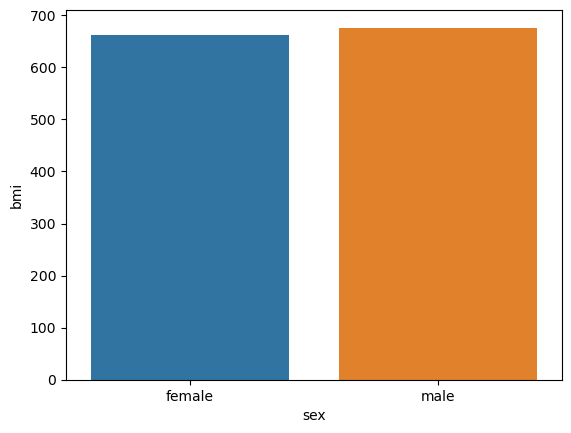

In [14]:
sns.barplot(df_gender_count, x = "sex", y = "bmi")

In [15]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


## I want to know the average bmi for gender

In [16]:
df_average_gender_bmi = df[["sex", "bmi"]].groupby("sex").mean().reset_index()

In [20]:
df_average_gender_bmi

,sex,bmi
0,female,30.377749
1,male,30.943129


<Axes: xlabel='sex', ylabel='bmi'>

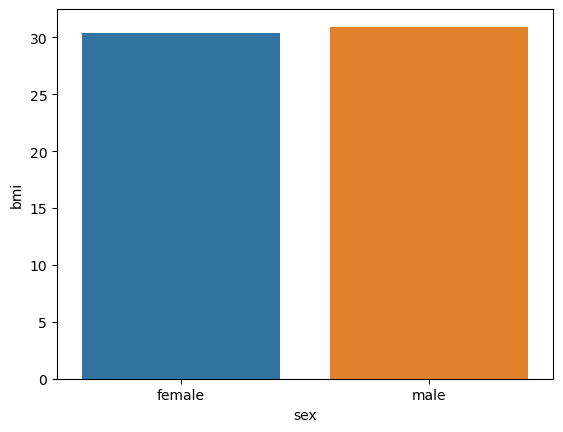

In [17]:
sns.barplot(df_average_gender_bmi, x = "sex", y = "bmi")

* Average bmi for males in higher than females

* Average claim amount for males and females

In [21]:
df[["sex", "charges"]].groupby("sex").mean()

,charges
sex,
female,12569.578844
male,13956.751178


In [22]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [23]:
# For Males
df[df["sex"] == "male"][["sex", "smoker"]].groupby("smoker").count()

,sex
smoker,
no,517
yes,159


In [24]:
159/676

0.23520710059171598

In [25]:
# For Females
df[df["sex"] == "female"][["sex", "smoker"]].groupby("smoker").count()

,sex
smoker,
no,547
yes,115


In [26]:
115/662

0.17371601208459214